Title

Import packages

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import re
import pandas as pd
from io import BytesIO
from pathlib import Path

In [22]:
# Setting parameters
Duration_Threshold = 1440
International_Stations = ["Luik", "Düsseldorf", "Aachen", "Brussel", "Liège"]

# Filtering the data
Disruption_Data = pd.read_csv('data/disruptions-2025.csv')

# Long_Disruptions = Disruption_Data[Disruption_Data["duration_minutes"] > Duration_Threshold]

National_Connections = Disruption_Data.copy()

for station in International_Stations:
    National_Connections = National_Connections[~National_Connections["ns_lines"].str.contains(station)]

Long_Disruptions = National_Connections.copy()

Long_Disruptions = National_Connections[National_Connections["duration_minutes"] > Duration_Threshold]



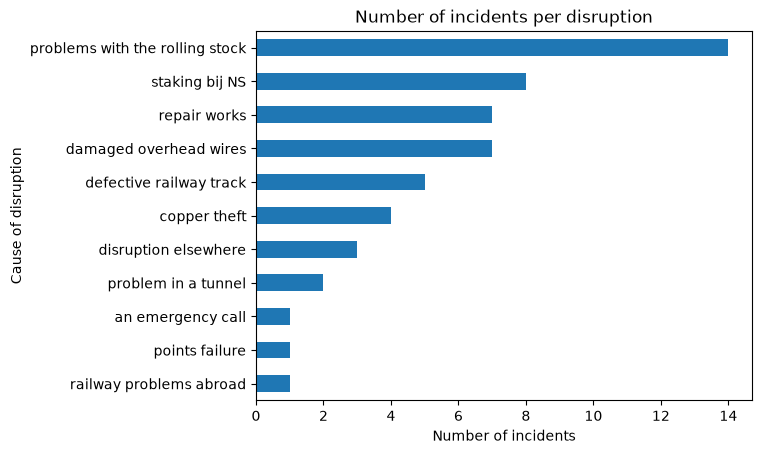

In [23]:
# Visualizing the number of incidents per disruption
Cause_Count = Long_Disruptions["cause_en"].value_counts()
Cause_Count.sort_values().plot(kind="barh")
plt.xlabel("Number of incidents")
plt.ylabel("Cause of disruption")
plt.title("Number of incidents per disruption")
plt.show()

In [24]:
Longest_10_Disruptions = National_Connections.sort_values(by="duration_minutes", ascending=False).head(30)
display(Longest_10_Disruptions[["duration_minutes", "ns_lines", "cause_en", "start_time", "rdt_lines"]])

,duration_minutes,ns_lines,cause_en,start_time,rdt_lines
490,13234.0,Heerlen - Maastricht,problems with the rolling stock,2025-01-23 03:47:16,Heerlen - Maastricht
5586,10876.0,Utrecht - Eindhoven,repair works,2025-10-30 11:14:42,'s-Hertogenbosch - Utrecht Centraal
4141,8300.0,Heerlen - Maastricht Randwyck,problems with the rolling stock,2025-08-12 06:51:14,Heerlen - Maastricht
4537,8244.0,Heerlen - Maastricht,problems with the rolling stock,2025-09-04 07:03:31,Heerlen - Maastricht
4232,8144.0,Hengelo - Bielefeld,problems with the rolling stock,2025-08-18 05:47:57,"Berlin Ostbahnhof - Hengelo, Bielefeld Hbf - H..."
677,6614.0,Heerlen - Maastricht,problems with the rolling stock,2025-02-01 09:51:44,Heerlen - Maastricht
393,5479.0,Heerlen - Maastricht Randwyck,problems with the rolling stock,2025-01-18 05:26:21,Heerlen - Maastricht
5644,5463.0,Schiphol - Utrecht,repair works,2025-11-03 03:57:17,"Amsterdam Centraal - Utrecht Centraal, Schipho..."
2959,4557.0,Dordrecht - Roosendaal,repair works,2025-06-06 22:08:18,Dordrecht - Roosendaal
4773,4378.0,Heerlen - Maastricht,problems with the rolling stock,2025-09-16 08:42:06,Heerlen - Maastricht


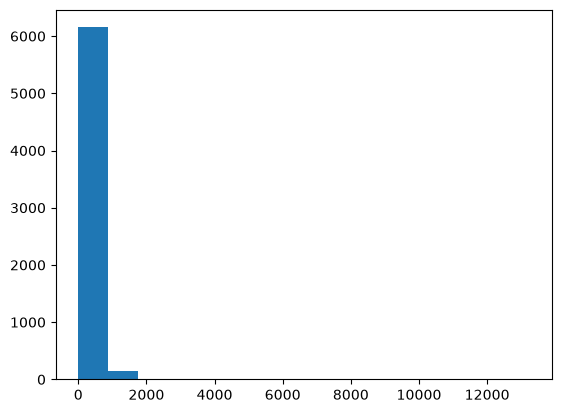

In [25]:
# plt.plot(National_Connections["duration_minutes"])
plt.hist(National_Connections["duration_minutes"], bins=15);

# plt.plot(National_Connections["duration_minutes"])

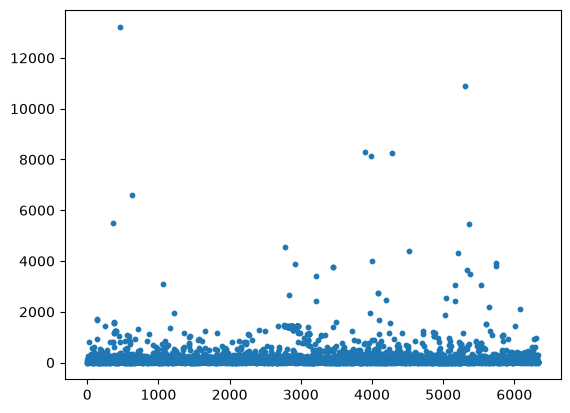

In [26]:
plt.scatter(
    range(len(National_Connections)),
    National_Connections["duration_minutes"],
    s=10
)

(0.0, 500.0)

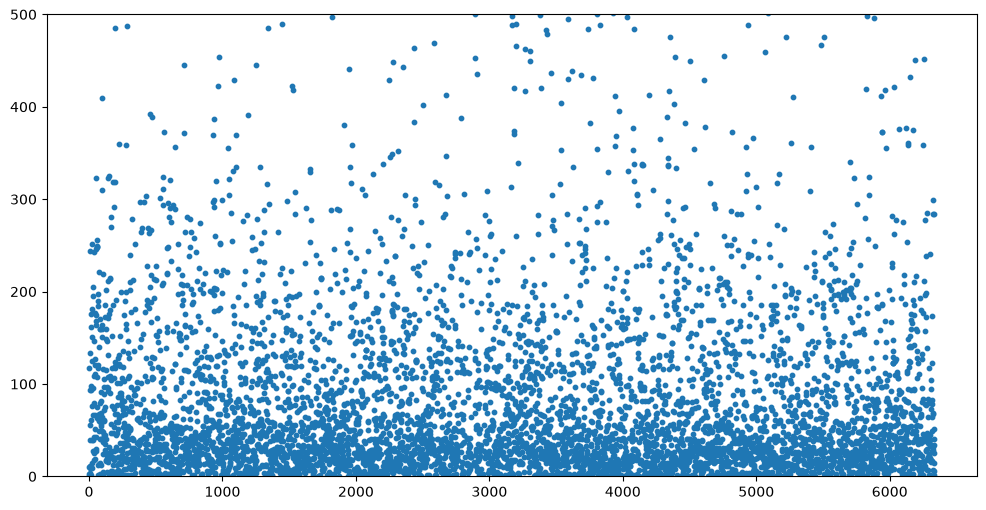

In [27]:
plt.figure(figsize=(12, 6))

plt.scatter(
    range(len(National_Connections)),
    National_Connections["duration_minutes"],
    s=10
)

plt.ylim(0, 500)

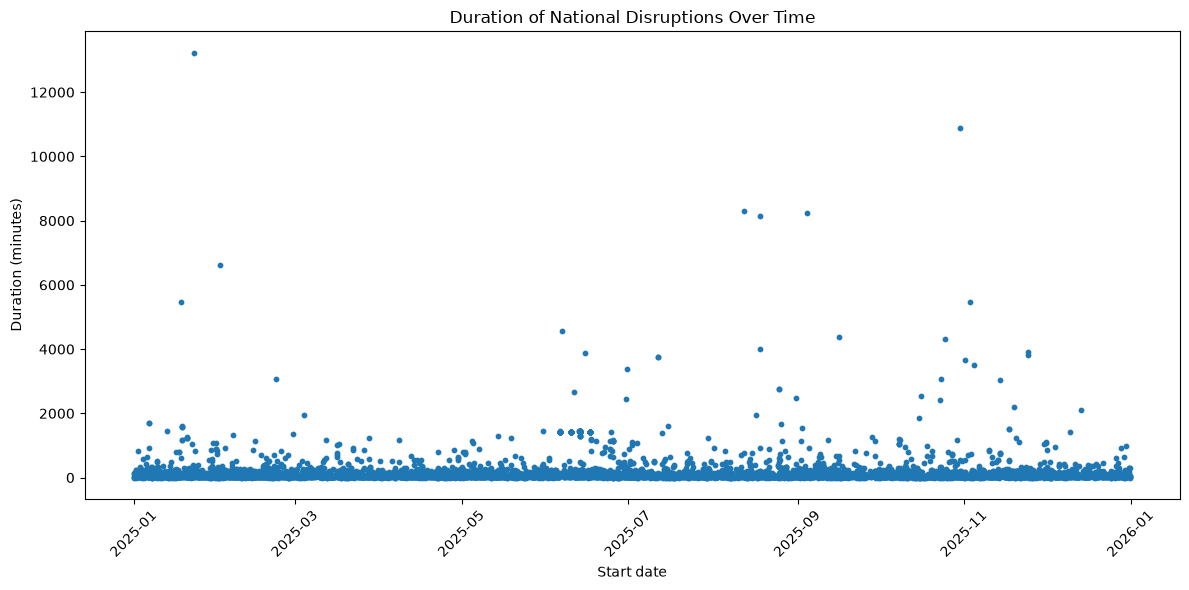

In [28]:
# Convert start_time to datetime
National_Connections["start_time"] = pd.to_datetime(
    National_Connections["start_time"]
)

# Plot duration against start date
plt.figure(figsize=(12, 6))

plt.scatter(
    National_Connections["start_time"],
    National_Connections["duration_minutes"],
    s=10
)

# plt.yscale("log")
plt.xlabel("Start date")
plt.ylabel("Duration (minutes)")
plt.title("Duration of National Disruptions Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
def read_daily_zip(zip_path):

    with zipfile.ZipFile(zip_path, "r") as archive:

        excel_files = [
            name for name in archive.namelist()
            if name.lower().endswith((".xlsx", ".xlsm"))
            and not name.startswith("__MACOSX/")
        ]

        if not excel_files:
            print(f"Geen Excelbestand gevonden: {zip_path.name}")
            return None

        # Read the first Excel file in this ZIP
        excel_bytes = BytesIO(archive.read(excel_files[0]))

        # Read date from the Overzicht sheet
        overview = pd.read_excel(
            excel_bytes,
            sheet_name="Overzicht",
            header=None
        )

        # Usually cell B2 contains:
        # 02-03-2023 tot en met 02-03-2023
        period_text = str(overview.iloc[1, 1])

        match = re.search(
            r"(\d{2}-\d{2}-\d{4})",
            period_text
        )

        if match:
            date = pd.to_datetime(
                match.group(1),
                format="%d-%m-%Y"
            )
        else:
            # Fall back to date in the Intensiteit sheet title
            intensity_raw = pd.read_excel(
                excel_bytes,
                sheet_name="Intensiteit",
                header=None
            )

            title = str(intensity_raw.iloc[3, 0])

            match = re.search(r"\d{4}-\d{2}-\d{2}", title)

            if not match:
                raise ValueError(
                    f"Could not determine date in {zip_path.name}"
                )

            date = pd.Timestamp(match.group(0))

        # Read hourly intensity table
        raw = pd.read_excel(
            excel_bytes,
            sheet_name="Intensiteit",
            header=None
        )

        # Row 4 contains column headers:
        # uur op de dag | Intensiteit | onbepaald (%)
        df = raw.iloc[5:, :2].copy()
        df.columns = ["time_interval", "intensity"]

        df = df.dropna(subset=["time_interval", "intensity"])

        # Keep rows that look like hourly intervals
        df = df[
            df["time_interval"].astype(str).str.match(
                r"^\d{2}:\d{2}\s*-\s*\d{2}:\d{2}$"
            )
        ].copy()

        df["intensity"] = pd.to_numeric(
            df["intensity"], errors="coerce"
        )
        df = df.dropna(subset=["intensity"])

        # Extract hour from e.g. "09:00 - 09:59"
        df["hour"] = df["time_interval"].str[:2].astype(int)

        df["date"] = date
        df["weekday"] = date.dayofweek

        return df[["date", "weekday", "hour", "intensity"]]

In [30]:
# Stel dat je de dataset inlaadt
df_2025 = pd.read_csv("data\disruptions-2025.csv")
# 1. De gewenste jaren inladen

# df_2023 = pd.read_csv("disruptions-2023.csv")
# df_2024 = pd.read_csv("disruptions-2024.csv")

# 2. Samenvoegen onder elkaar
df = pd.concat([df_2025], ignore_index=True)
#display(df.head())

lang = df[df['duration_minutes' ] >= 60*24]
lang11 = lang[lang['ns_lines'] == 'Utrecht - Eindhoven' ]
lang11 = lang11[['rdt_lines', 'duration_minutes', 'cause_nl', 'start_time', 'end_time']]



display(lang11)

print(lang11['start_time'].iloc[0])
lang = lang[['rdt_lines', 'duration_minutes', 'cause_nl', 'start_time']]



#display(lang)

# Exporteren naar CSV
lang.to_csv("trajectwerkzaamheden langer dan 1 dag.csv", index=False, encoding="utf-8-sig")
print("Bestand opgeslagen als 'trajectwerkzaamheden.csv'")

,rdt_lines,duration_minutes,cause_nl,start_time,end_time
5586,'s-Hertogenbosch - Utrecht Centraal,10876.0,herstelwerkzaamheden,2025-10-30 11:14:42,2025-11-07 00:31:03


2025-10-30 11:14:42
Bestand opgeslagen als 'trajectwerkzaamheden.csv'


In [31]:

# # MAAK IN DE FOLDER MET JE NOTEBOOK EEN MAPJE 'data', EN DOE DAARIN DE DAGEN ALS ZIP FILES MET NAMEN 'maandag.zip', ...
# # VOOR DE REFERENTIE, PAK DE WEEK ERVOOR EN DOE DIE IN DEZELFDE MAP MET NAMEN 'maandag week ervoor.zip', ...

# # --------------------------------------------------
# # 1. Load the data
# # --------------------------------------------------

# DATA_FOLDER = Path("data/data_utr-db/Unplanned")

# df_current = pd.concat([
#     read_daily_zip(f)
#     for f in DATA_FOLDER.glob("*.zip")
#     if "gem" not in f.stem.lower()
# ])

# df_previous = pd.concat([
#     read_daily_zip(f)
#     for f in DATA_FOLDER.glob("*.zip")
#     if "gem" in f.stem.lower()
# ])

# for data in [df_current, df_previous]:
#     data["plot_time"] = (
#         pd.Timestamp("2024-01-01")
#         + pd.to_timedelta(data["weekday"], unit="D")
#         + pd.to_timedelta(data["hour"], unit="h")
#     )

#     data.sort_values("plot_time", inplace=True)
# print(len(df_previous))
# print(len(df_current))
# # --------------------------------------------------
# # 2. Align both weeks by weekday and hour
# # --------------------------------------------------

# for data in [df_current, df_previous]:
#     data["plot_time"] = (
#         pd.Timestamp("2024-01-01")
#         + pd.to_timedelta(data["weekday"], unit="D")
#         + pd.to_timedelta(data["hour"], unit="h")
#     )

# # --------------------------------------------------
# # 3. Plot both weeks
# # --------------------------------------------------

# # Combineer meerdere waarden per timestamp door het gemiddelde te nemen
# df_current = (
#     df_current
#     .groupby("plot_time", as_index=False)["intensity"]
#     .sum()
# )

# df_previous = (
#     df_previous
#     .groupby("plot_time", as_index=False)["intensity"]
#     .sum()
# )


# fig, ax = plt.subplots(figsize=(16, 7))

# ax.plot(
#     df_previous["plot_time"],
#     df_previous["intensity"],
#     marker = 'o',
#     markersize = 3,
#     linestyle = '',
#     label="Average week"
# )

# ax.fill_between(
#     df_previous["plot_time"],
#     df_previous["intensity"],
#     alpha=0.2
# )

# ax.plot(
#     df_current["plot_time"],
#     df_current["intensity"],
#     marker = 'o',
#     markersize = 3,
#     linestyle = '',
#     label="Disruption week"
# )

# ax.fill_between(
#     df_current["plot_time"],
#     df_current["intensity"],
#     alpha=0.2
# )
# # Mark the disruption start
# disruption_start = pd.Timestamp(lang11.start_time.iloc[0])
# ax.axvline(
#     pd.Timestamp("2024-01-01")
#     + pd.Timedelta(days=disruption_start.dayofweek)
#     + pd.Timedelta(
#         hours=disruption_start.hour
#         + disruption_start.minute / 60
#     ),
#     color="red",
#     linestyle="--",
#     label="Start disruption"
# )
# start = pd.Timestamp(lang11.start_time.iloc[0])
# end = pd.Timestamp(lang11.end_time.iloc[0])


# # Format the plot
# ax.set_xticks(pd.date_range("2024-01-01", periods=7, freq="D"))
# ax.set_xticklabels([
#     "Maandag", "Dinsdag", "Woensdag", "Donderdag",
#     "Vrijdag", "Zaterdag", "Zondag"
# ])

# ax.set_xlim(pd.Timestamp("2024-01-01"),
#             pd.Timestamp("2024-01-08"))

# ax.set_xlabel("Day of the week")
# ax.set_ylabel("Traffic intensity (vehicles per hour)")
# ax.set_title("Traffic intensity: avg week vs disruption week")
# ax.legend()
# ax.grid(alpha=0.3)

# plt.tight_layout()
# plt.show()

Average week: 672 observations
Disruption week: 672 observations


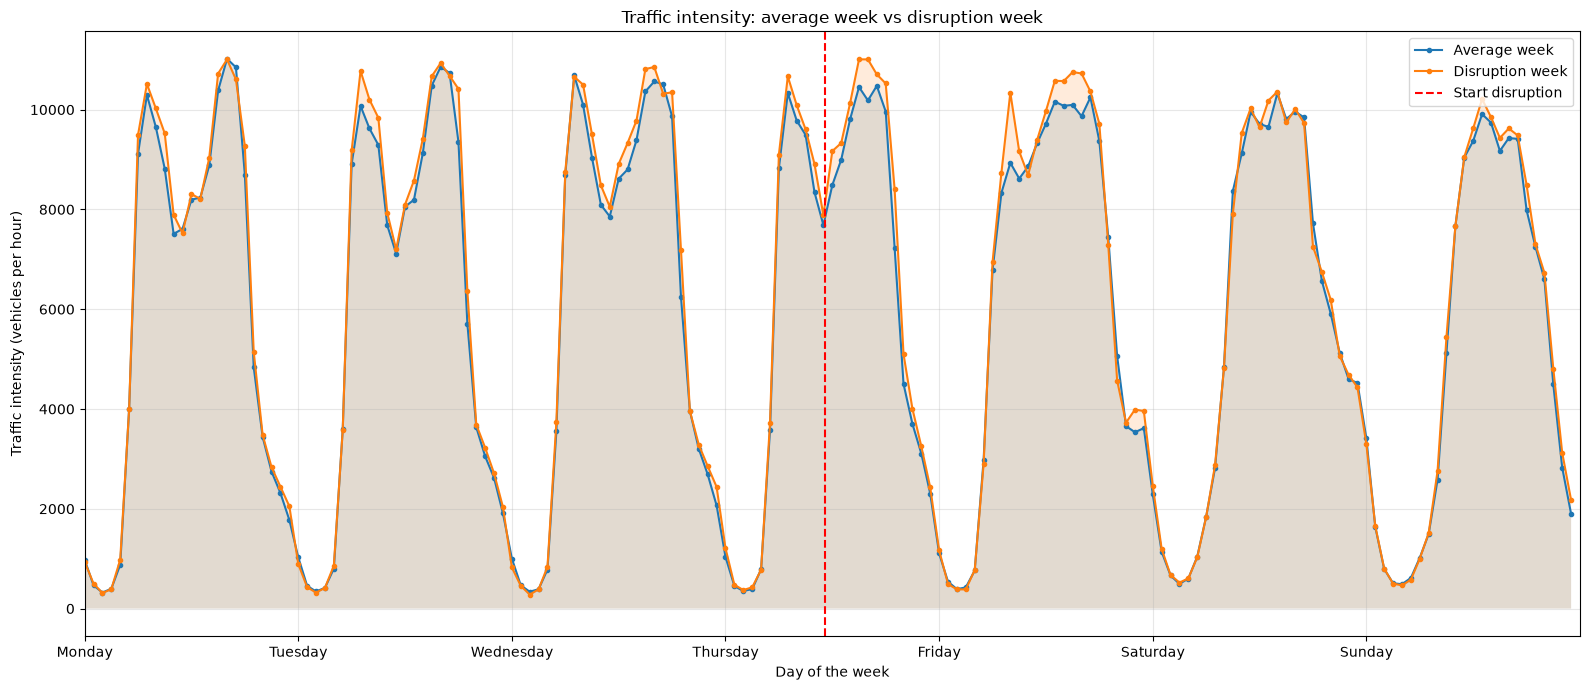

In [32]:

# ==================================================
# 1. Function to read one daily ZIP file
# ==================================================

def read_daily_zip(zip_path):

    with zipfile.ZipFile(zip_path, "r") as archive:

        # Find Excel files inside the ZIP
        excel_files = [
            name for name in archive.namelist()
            if name.lower().endswith((".xlsx", ".xlsm"))
            and not name.startswith("__MACOSX/")
        ]

        if not excel_files:
            print(f"No Excel file found: {zip_path.name}")
            return None

        # Read the first Excel file
        excel_bytes = BytesIO(archive.read(excel_files[0]))

        # Read the date from the Overzicht sheet
        overview = pd.read_excel(
            excel_bytes,
            sheet_name="Overzicht",
            header=None
        )

        # Usually cell B2 contains the date
        period_text = str(overview.iloc[1, 1])

        match = re.search(r"(\d{2}-\d{2}-\d{4})", period_text)

        if match:
            date = pd.to_datetime(
                match.group(1),
                format="%d-%m-%Y"
            )

        else:
            # If necessary, find the date in the Intensiteit sheet
            intensity_raw = pd.read_excel(
                excel_bytes,
                sheet_name="Intensiteit",
                header=None
            )

            title = str(intensity_raw.iloc[3, 0])
            match = re.search(r"\d{4}-\d{2}-\d{2}", title)

            if not match:
                raise ValueError(
                    f"Could not determine date in {zip_path.name}"
                )

            date = pd.Timestamp(match.group(0))

        # Read the hourly intensity table
        raw = pd.read_excel(
            excel_bytes,
            sheet_name="Intensiteit",
            header=None
        )

        # Extract the hourly intervals and intensity values
        df = raw.iloc[5:, :2].copy()
        df.columns = ["time_interval", "intensity"]

        df = df.dropna(
            subset=["time_interval", "intensity"]
        )

        # Keep rows that contain hourly intervals
        df = df[
            df["time_interval"].astype(str).str.match(
                r"^\d{2}:\d{2}\s*-\s*\d{2}:\d{2}$"
            )
        ].copy()

        # Convert intensity to numeric values
        df["intensity"] = pd.to_numeric(
            df["intensity"],
            errors="coerce"
        )

        df = df.dropna(subset=["intensity"])

        # Extract the hour, e.g. 09 from "09:00 - 09:59"
        df["hour"] = df["time_interval"].str[:2].astype(int)

        # Add date information
        df["date"] = date
        df["weekday"] = date.dayofweek

        return df[["date", "weekday", "hour", "intensity"]]


# ==================================================
# 2. Load the data from both folders
# ==================================================

BASE_FOLDER = Path("data/data_utr-db/Unplanned")


def load_week(folder):

    # Find all ZIP files in the folder
    zip_files = sorted(folder.glob("*.zip"))

    if not zip_files:
        raise FileNotFoundError(
            f"No ZIP files found in: {folder.resolve()}"
        )

    # Read each ZIP file
    daily_data = [
        read_daily_zip(zip_file)
        for zip_file in zip_files
    ]

    # Remove files that did not contain usable data
    daily_data = [
        data for data in daily_data
        if data is not None and not data.empty
    ]

    if not daily_data:
        raise ValueError(f"No usable data found in: {folder}")

    # Combine all daily data into one DataFrame
    data = pd.concat(daily_data, ignore_index=True)

    # Align the days to the same Monday-to-Sunday timeline
    data["plot_time"] = (
        pd.Timestamp("2024-01-01")
        + pd.to_timedelta(data["weekday"], unit="D")
        + pd.to_timedelta(data["hour"], unit="h")
    )

    return data.sort_values("plot_time")


# Load the reference week and disruption week
df_previous = load_week(BASE_FOLDER / "Average")
df_current = load_week(BASE_FOLDER / "Delay_week")

print("Average week:", len(df_previous), "observations")
print("Disruption week:", len(df_current), "observations")


# ==================================================
# 3. Combine observations for each weekday and hour
# ==================================================

df_previous = (
    df_previous
    .groupby("plot_time", as_index=False)["intensity"]
    .sum()
)

df_current = (
    df_current
    .groupby("plot_time", as_index=False)["intensity"]
    .sum()
)


# ==================================================
# 4. Determine the disruption start time
# ==================================================

disruption_start = pd.Timestamp(lang11.start_time.iloc[0])

disruption_time = (
    pd.Timestamp("2024-01-01")
    + pd.Timedelta(days=disruption_start.dayofweek)
    + pd.Timedelta(
        hours=disruption_start.hour,
        minutes=disruption_start.minute
    )
)


# ==================================================
# 5. Plot both weeks
# ==================================================

fig, ax = plt.subplots(figsize=(16, 7))

# Plot the average week
ax.plot(
    df_previous["plot_time"],
    df_previous["intensity"],
    marker="o",
    markersize=3,
    label="Average week"
)

ax.fill_between(
    df_previous["plot_time"],
    df_previous["intensity"],
    alpha=0.15
)

# Plot the disruption week
ax.plot(
    df_current["plot_time"],
    df_current["intensity"],
    marker="o",
    markersize=3,
    label="Disruption week"
)

ax.fill_between(
    df_current["plot_time"],
    df_current["intensity"],
    alpha=0.15
)

# Mark the start of the disruption
ax.axvline(
    disruption_time,
    color="red",
    linestyle="--",
    label="Start disruption"
)


# ==================================================
# 6. Format the plot
# ==================================================

ax.set_xticks(
    pd.date_range("2024-01-01", periods=7, freq="D")
)

ax.set_xticklabels([
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
])

ax.set_xlim(
    pd.Timestamp("2024-01-01"),
    pd.Timestamp("2024-01-08")
)

ax.set_xlabel("Day of the week")
ax.set_ylabel("Traffic intensity (vehicles per hour)")
ax.set_title("Traffic intensity: average week vs disruption week")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
